In [20]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

In [5]:
%cd /emmy-noether/home/mf671/DATA/ERA5/gr_tracking
!ls

/emmy-noether/home/mf671/DATA/ERA5/gr_tracking
dictionaries
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1940-2023.nc


In [26]:
version = 'DAV'
DSs = []
dics = []
np_arrays = []
for version in ['DAV','GHA']:
    DSs.append(xr.open_dataset('ERA5_northem_2.5x2.5_zg_'+version+'_tracked_daily_1940-2023.nc'))
    dics.append(np.load('dictionaries/ERA5_northem_2.5x2.5_zg_'+version+'_tracked_daily_1940-2023_DIC.npy',allow_pickle=True))
    np_arrays.append(DSs[-1][version+'_tracked'].values)

times = DSs[0]['time']
lats = DSs[0]['lat']
lons = DSs[0]['lon']

### selecting the events crossing Greenland

In [28]:
#Define rectangular mask and plon, plat
# Define the resolution
lat_resolution = 2.5  # 2.5 degrees
lon_resolution = 2.5  # 2.5 degrees

# Define the global latitude and longitude ranges
latitudes = np.arange(0, 91, lat_resolution)  # From 0°N to 90°N
longitudes = np.arange(-180, 180, lon_resolution)  # From -180°E to 180°E

# Initialize a global mask with zeros
mask = np.zeros((len(latitudes), len(longitudes)))

# Define the rectangular bounding box around Greenland (60°–80°N, 20°–80°W)
lat_min, lat_max = 67, 80
lon_min, lon_max = -70, -20
plon = (lon_max + lon_min)/2
#plat = (lat_max + lat_min)/2

# Assign 1 to grid points within the bounding box
for i, lat in enumerate(latitudes):
    if lat_min <= lat <= lat_max:
        for j, lon in enumerate(longitudes):
            if lon_min <= lon <= lon_max:
                mask[i, j] = 1

# Convert the mask to an xarray DataArray
mask_xr = xr.DataArray(mask, coords=[latitudes, longitudes], dims=["lat", "lon"])
mask_bool = mask_xr.data == 1

In [29]:
#create a list of labels for each IBI
#element 0 is DAV, 1 is GHA, 2 is MIX
dics_to_save = [[],[]]
labels = [[],[]]
timings = [[],[]]
min_pers = (3,3)
for t,time in tqdm(enumerate(times)):
    if t > len(times.values)-5:
        break
    for i,arr in enumerate(np_arrays):
        labels_of_the_day = np.unique(arr[t,mask_bool])
        for label in labels_of_the_day:
            check_cond = []
            for k in range(min_pers[i]):
                #check_cond.append(np.sum(arr[t+k,mask_bool]==label)/np.sum(mask_bool) > 0.1)
                check_cond.append(np.any(arr[t+k,mask_bool]==label))
            if label not in labels[i] and np.all(check_cond) and label!=0:
                dics_to_save[i].append(dics[i][label])
                dics_to_save[i][-1]['time_arrival_GR'] = t
                dics_to_save[i][-1]['day_arrival_GR'] = time
                dics_to_save[i][-1]['original_label'] = label
                labels[i].append(label)
                timings[i].append(t)
                dics[i][label]['day_of_arrival'] = time

30677it [00:17, 1773.81it/s]


### computing the WBI monthly distribution

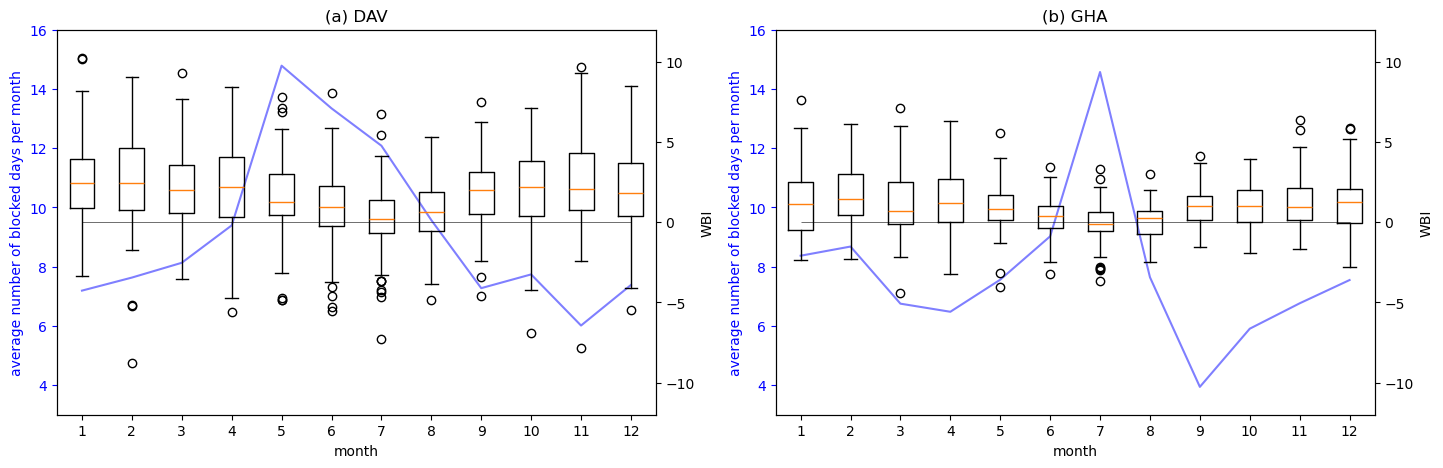

In [112]:
fig, axs = plt.subplots(nrows=1,ncols=2,figsize=(17, 5))

#initialize list of lists
IDX = 0 #0 is DAV, 1 is GHA
WBIs = []
for i in range(12):
    WBIs.append([])

N_events = np.zeros(12)
#loop over the dictionary elements
for element in dics_to_save[IDX]:
    time = element['day_arrival_GR']
    month = int(str(time.values)[5:7])
    WBIs[month-1].append(sum(element['WBI'])/len(element['WBI']))
    N_events[month-1] += element['persistence']  


axs[0].set_title('(a) DAV')    
axs[0].plot(np.arange(1,13),N_events/84,color='blue',alpha=0.5)
axs[0].set_ylabel('average number of blocked days per month')
axs[0].set_xlabel('month')
axs[0].set_ylim((3,16))
axs[0].tick_params(axis='y', colors='blue')
axs[0].yaxis.label.set_color('blue')

axs0bis = axs[0].twinx()

axs0bis.boxplot(WBIs)
axs0bis.hlines(0,1,12,color='black',linewidths=0.5,alpha=0.8)
axs0bis.set_ylabel('WBI')
axs0bis.set_ylim((-12,12))

#initialize list of lists
IDX = 1 #0 is DAV, 1 is GHA
WBIs = []
for i in range(12):
    WBIs.append([])

N_events = np.zeros(12)
#loop over the dictionary elements
for element in dics_to_save[IDX]:
    time = element['day_arrival_GR']
    month = int(str(time.values)[5:7])
    WBIs[month-1].append(sum(element['WBI'])/len(element['WBI']))
    N_events[month-1] += element['persistence']    

axs[1].set_title('(b) GHA')    
axs[1].plot(np.arange(1,13),N_events/84,color='blue',alpha=0.5)
axs[1].set_ylabel('average number of blocked days per month')
axs[1].set_xlabel('month')
axs[1].set_ylim((3,16))
axs[1].tick_params(axis='y', colors='blue')
axs[1].yaxis.label.set_color('blue')


axs1bis = axs[1].twinx()

axs1bis.boxplot(WBIs)
axs1bis.hlines(0,1,12,color='black',linewidths=0.5,alpha=0.8)
axs1bis.set_ylabel('WBI')
axs1bis.set_ylim((-12,12))

plt.savefig("/emmy-noether/home/mf671/github/greenland_blocking/PLOTS/FigureA1.png",dpi=400)
